<h2 style="color:green" align="center">Predicting if a person would buy life insurnace based on his age using logistic regression</h2>

Above is a binary logistic regression problem as there are only two possible outcomes (i.e. if person buys insurance or he/she doesn't).

---
# Part 1 — Quick start: will a person buy life insurance?

📘 **Problem.** We want to predict whether a person **buys life insurance (1)** or **does not (0)** from their **age**.

This is a **binary classification** problem: the output has only two possible values, $y \in \{0, 1\}$.

**Why not plain linear regression?** A straight line $y = mx + b$ can output values like $-0.4$ or $1.7$, which make no sense as a "yes/no" answer or as a probability. Logistic regression keeps the linear part but **squashes** it into the range $(0,1)$ with the **sigmoid** function, so the output can be read as a probability:

$$
h_\theta(x) = P(y = 1 \mid x;\theta) = \sigma(\theta^T x) = \frac{1}{1+e^{-\theta^T x}}
$$

The whole model at a glance (from the lecture slides):

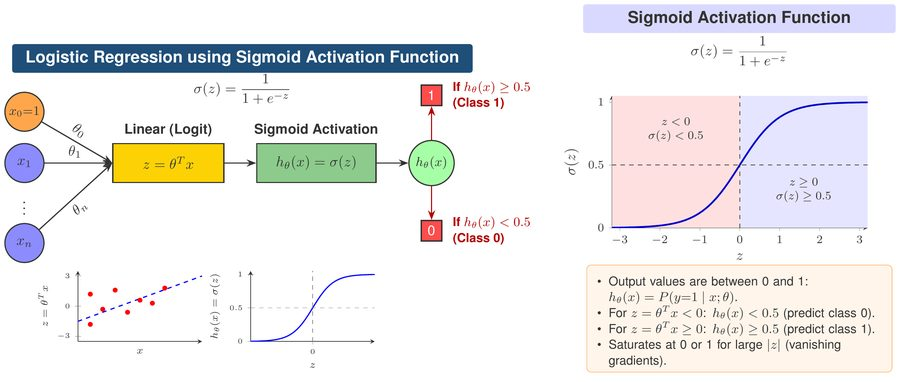

**Read the diagram left → right:**
1. Inputs $x_1,\dots,x_n$ (plus a constant $x_0 = 1$ for the bias) are multiplied by weights $\theta_0,\dots,\theta_n$.
2. **Linear part (logit):** $z = \theta^T x = \theta_0 + \theta_1 x_1 + \dots + \theta_n x_n$
3. **Sigmoid activation:** $h_\theta(x) = \sigma(z)$ — a number between 0 and 1.
4. **Decision rule:** predict class **1** if $h_\theta(x) \ge 0.5$, otherwise class **0**.

Let's first see this working with scikit-learn, then in Parts 2–6 we will open the "black box" and build it ourselves.

In [24]:
import pandas as pd
from matplotlib import pyplot as plt
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
from sklearn.linear_model import LogisticRegression


# Load a dataset and visualize

In [25]:
df= pd.read_csv("insurance_data.csv")
df.head(5)

,age,bought_insurance
0,22,0
1,25,0
2,47,1
3,52,0
4,46,1


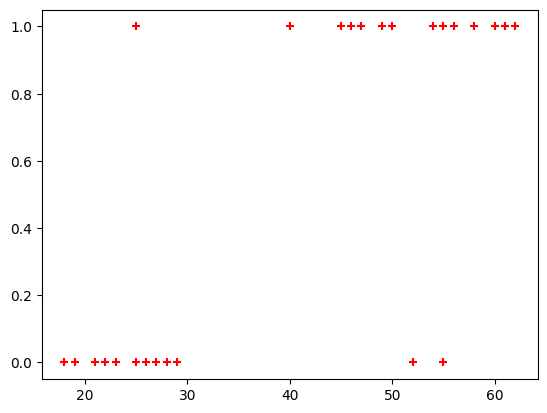

In [26]:
plt.scatter(df.age,df.bought_insurance,marker='+',color='red')

In [27]:
X_train, X_test, y_train, y_test = train_test_split(df[['age']],df.bought_insurance,train_size=0.8,random_state=67)

In [28]:
print(X_test)


    age
17   58
23   45
25   54
19   18
11   28
2    47


### Insurance Purchase Prediction

Create a Logistic Regression classification model to predict whether a customer will purchase an insurance policy based on customer detail  age

The target variable should indicate:
- `1` – Customer will purchase insurance.
- `0` – Customer will not purchase insurance.

In [29]:

model= LogisticRegression()

### Train the Logistic Regression Model

Train the Logistic Regression model using the training dataset. Use `X_train` as the input features (customer details) and `y_train` as the target labels (whether the customer purchases insurance or not).

The `fit()` method enables the model to learn patterns from the training data.

In [30]:
model.fit(X_train,y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`mul

### 🧪 1.4 Make predictions
📘 Two kinds of output:
- `predict_proba(X)` → probabilities. Column 0 = $P(y=0)$, column 1 = $P(y=1)$. Each row adds up to 1.
- `predict(X)` → the class label, obtained by applying the **0.5 threshold** to column 1.

In [31]:
y_predicted = model.predict(X_test)
print(y_predicted)

[1 1 1 0 0 1]


In [32]:
model.predict_proba(X_test)

array([[0.11715472, 0.88284528],
       [0.37187323, 0.62812677],
       [0.17371678, 0.82628322],
       [0.9296796 , 0.0703204 ],
       [0.80712245, 0.19287755],
       [0.31989365, 0.68010635]])

In [33]:
model.score(X_test,y_test)

1.0

**model.coef_ indicates value of m in y=m*x + b equation**

In [34]:
model.coef_

array([[0.11503581]])

**model.intercept_ indicates value of b in y=m*x + b equation**

In [35]:
model.intercept_

array([-4.65242264])

**Lets defined sigmoid function now and do the math with hand**

In [36]:
import math
def sigmoid(x):
  return 1 / (1 + math.exp(-x))

In [37]:
def prediction_function(age):
    z = 0.042 * age - 1.53 # 0.04150133 ~ 0.042 and -1.52726963 ~ -1.53
    y = sigmoid(z)
    return y

In [38]:
age = 21
prediction_function(age)

0.34344037417764955

**0.485 is less than 0.5 which means person with 35 age will *not* buy insurance**
**0.485 is more than 0.5 which means person with 43 will buy the insurance**

In [39]:
age = 43
prediction_function(age)

0.568565299077705

---
# The loss and cost functions

### Binary Cross-Entropy (log loss) for ONE example
The **Binary Cross-Entropy Loss** (also called **log loss**) measures how wrong one predicted probability is. With $h = h_\theta(x)$ and true label $y \in \{0,1\}$:

$$ \boxed{L\big(h_\theta(x), y\big) = -\Big(y \log h_\theta(x) + (1-y)\log\big(1-h_\theta(x)\big)\Big)} $$

Because $y$ is either 0 or 1, only **one** of the two terms is ever "switched on":

| True label | Loss becomes | What the model must do to make the loss small |
|---|---|---|
| $y = 1$ | $L = -\log h_\theta(x)$ | make $h_\theta(x)$ **large** (close to 1) |
| $y = 0$ | $L = -\log\big(1-h_\theta(x)\big)$ | make $h_\theta(x)$ **small** (close to 0) |

💡 $\log$ here is the **natural log** (`np.log`). A confident **wrong** prediction is punished very heavily: as $h \to 0$ when $y=1$, the loss $\to \infty$.

🧪 See the two branches of the loss:

###  Exercise — fill in the loss column (from the slides)
Compute $L$ for each row on paper, then run the next cell to check.

| True label $y^{(i)}$ | Predicted probability $h_\theta(x^{(i)})$ | Loss $L$ |
|:---:|:---:|:---:|
| 1 | 0.9 | ? |
| 0 | 0.1 | ? |
| 1 | 0.4 | ? |
| 0 | 0.7 | ? |

<details><summary><b>Show answers</b></summary>

| y | h | Loss |
|:-:|:-:|:-:|
| 1 | 0.9 | −log(0.9) = **0.1054** (good prediction → small loss) |
| 0 | 0.1 | −log(1 − 0.1) = **0.1054** (good prediction → small loss) |
| 1 | 0.4 | −log(0.4) = **0.9163** (wrong side of 0.5 → larger loss) |
| 0 | 0.7 | −log(1 − 0.7) = **1.2040** (wrong side of 0.5 → largest loss) |

Average (this is the cost J) = (0.1054 + 0.1054 + 0.9163 + 1.2040) / 4 ≈ **0.5827**
</details>


# Step 1: Load dataset



# Encode Gender: Male = 1, Female = 0

# Prepare the X and Y

In [40]:
X = df[['age']].values
y = df['bought_insurance'].values.reshape(-1, 1)

# Normalize the feature and add an intercept column.
X = (X - X.mean(axis=0)) / X.std(axis=0)
X = np.hstack([np.ones((X.shape[0], 1)), X])
print(X.shape)
print(y.shape)

(27, 2)
(27, 1)


# The cost function for the WHOLE dataset
The **cost** $J(\theta)$ is simply the **average loss** over all $m$ training examples:

$$ \boxed{J(\theta) = -\frac{1}{m}\sum_{i=1}^{m}\Big[\,y^{(i)}\log h_\theta(x^{(i)}) + \big(1-y^{(i)}\big)\log\big(1-h_\theta(x^{(i)})\big)\Big]} $$

**Notation used in this lab**

| Symbol | Meaning |
|---|---|
| $J(\theta)$ | Cost function (depends on the parameters $\theta$) |
| $m$ | Number of training examples |
| $n$ | Number of features |
| $x^{(i)}$ | Feature vector of the $i$-th example (with $x_0^{(i)} = 1$) |
| $y^{(i)}$ | True label of the $i$-th example (0 or 1) |
| $\theta$ | Parameter vector $[\theta_0, \theta_1, \dots, \theta_n]^T$ ($\theta_0$ = bias) |
| $z^{(i)} = \theta^T x^{(i)}$ | Linear score (logit) of the $i$-th example |
| $h_\theta(x^{(i)}) = \sigma(z^{(i)})$ | Predicted probability for the $i$-th example |
| $\sigma(\cdot)$ | Sigmoid activation function |
| $\alpha$ | Learning rate |

🎯 **Goal of training:** find the $\theta$ that makes $J(\theta)$ as small as possible. For logistic regression, $J(\theta)$ is **convex** (bowl-shaped), so gradient descent can reach the global minimum.

In [41]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))


def compute_loss(y, y_pred):
    m = len(y)
    epsilon = 1e-8  # avoid log(0)
    return - (1/m) * np.sum(y * np.log(y_pred + epsilon) + (1-y) * np.log(1 - y_pred + epsilon))



# ---------------------------
# Step 4: Gradient Descent
# ---------------------------

---
# Deriving the gradient with the chain rule

📘 To minimise $J(\theta)$ with gradient descent we need $\dfrac{\partial L}{\partial \theta_j}$ — how the loss changes when we nudge one parameter. The loss depends on $\theta_j$ **through a chain**:

$$ \theta_j \;\longrightarrow\; z = \theta^T x \;\longrightarrow\; h_\theta(x) = \sigma(z) \;\longrightarrow\; L(h_\theta(x), y) $$

So by the **chain rule**:

$$ \frac{\partial L}{\partial \theta_j} = \frac{\partial L}{\partial h_\theta(x)} \cdot \frac{\partial h_\theta(x)}{\partial z} \cdot \frac{\partial z}{\partial \theta_j} $$

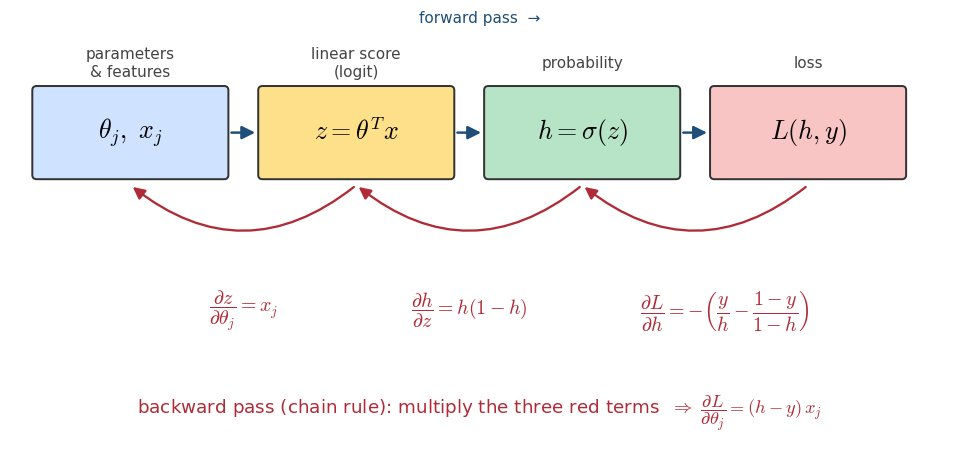



# Algorithm: Gradient Descent for Logistic Regression


\begin{array}{ll}
\textbf{Input:} & X,\ y,\ \alpha=0.01,\ T=1000\\
\textbf{Output:} & \theta,\ \text{loss\_history}
\end{array}


\begin{aligned}
&\textbf{Begin}\\
&\quad m \gets \text{number of samples in } X\\
&\quad n \gets \text{number of features in } X\\
&\quad \theta \gets \mathbf{0}_{n\times 1}\\
&\quad \text{loss\_history} \gets [\,]\\[2pt]
&\quad \textbf{For } t=1 \textbf{ to } T \textbf{ do}\\
&\qquad z \gets X\theta\\
&\qquad \hat{y} \gets \sigma(z)
       = \frac{1}{1+e^{-z}}\\
&\qquad e \gets \hat{y}-y\\
&\qquad g \gets \frac{1}{m}X^{\top}e\\
&\qquad \theta \gets \theta-\alpha g\\
&\qquad L \gets \operatorname{ComputeLoss}(y,\hat{y})\\
&\qquad \text{Append } L \text{ to loss\_history}\\
&\quad \textbf{End For}\\[2pt]
&\quad \textbf{Return } \theta,\ \text{loss\_history}\\
&\textbf{End}
\end{aligned}
\]


In [42]:

def gradient_descent(X, y, learning_rate=0.01, num_iterations=1000):
    m = X.shape[0]
    n = X.shape[1]
    theta = np.zeros((n,1))  # Initialize weights
    loss_history = []

    for i in range(num_iterations):
        z = np.dot(X, theta)
        y_pred = sigmoid(z)
        loss = compute_loss(y, y_pred)
        loss_history.append(loss)

        # Compute gradients
        gradients = (1/m) * np.dot(X.T, (y_pred - y))
        # Update weights
        theta -= learning_rate * gradients

    return theta, loss_history
       
        
        
    




# ---------------------------
# Step 5: Train Model
# ---------------------------

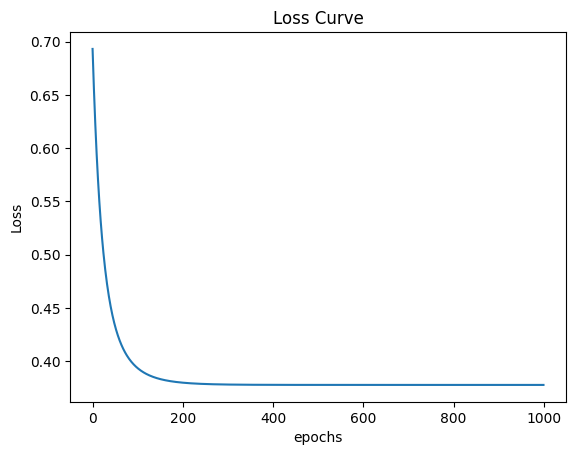

In [43]:
theta, loss_history = gradient_descent(X, y, learning_rate=0.1, num_iterations=1000)

# ---------------------------
# Step 6: Predictions
# ---------------------------
y_pred_prob = sigmoid(np.dot(X, theta))
y_pred = (y_pred_prob >= 0.5).astype(int)

# ---------------------------
# Step 7: Plot Loss Curve
# ---------------------------
plt.plot(loss_history)
plt.xlabel("epochs")
plt.ylabel("Loss")
plt.title("Loss Curve")
plt.show()

### Precision, Recall, F1-score and Accuracy

| Metric | Formula | Question it answers |
|---|---|---|
| **Accuracy** | $\dfrac{TP + TN}{TP + TN + FP + FN}$ | What fraction of *all* predictions are correct? (overall correctness) |
| **Precision** | $\dfrac{TP}{TP + FP}$ | Of everything I *predicted* positive, how much really is positive? (accuracy of the positive predictions) |
| **Recall** (Sensitivity, TPR) | $\dfrac{TP}{TP + FN}$ | Of all *actual* positives, how many did I catch? |
| **F1-score** | $2 \times \dfrac{\text{Precision} \times \text{Recall}}{\text{Precision} + \text{Recall}}$ | Harmonic mean — balances precision and recall; useful when classes are **imbalanced** |

💡 **When to care about which?**
- **High recall** matters when *missing* a positive is costly (disease screening, fraud detection).
- **High precision** matters when a *false alarm* is costly (spam filter deleting real emails).

🔗 More: https://developers.google.com/machine-learning/crash-course/classification/accuracy-precision-recall

🧪 Compute the metrics **from scratch** and compare with scikit-learn's `classification_report`:

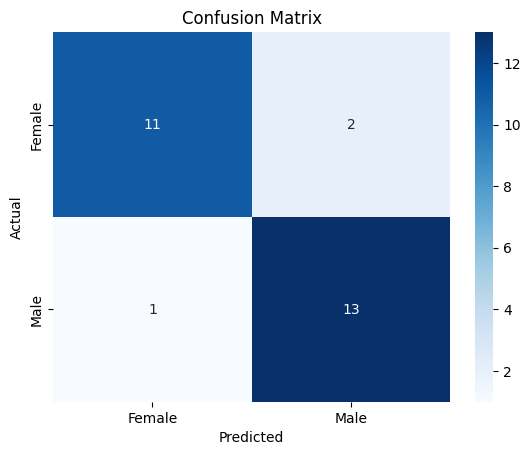

              precision    recall  f1-score   support

      Female       0.92      0.85      0.88        13
        Male       0.87      0.93      0.90        14

    accuracy                           0.89        27
   macro avg       0.89      0.89      0.89        27
weighted avg       0.89      0.89      0.89        27



In [44]:
# ---------------------------
# Step 8: Cousion Matrix
# ---------------------------
cm = confusion_matrix(y, y_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Female", "Male"],
            yticklabels=["Female", "Male"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

# ---------------------------
# Step 9: Classification Report
# ---------------------------
print(classification_report(y, y_pred, target_names=["Female", "Male"]))

In [45]:
plt.figure(figsize=(8, 5))
for lr in [0.001, 0.01, 0.1, 1.0, 5.0]:
    _, hist = gradient_descent(X, y, learning_rate=lr, num_iterations=300)
    plt.plot(hist, label=f"α = {lr}")
plt.xlabel("Epochs"); plt.ylabel("Loss"); plt.title("Effect of learning rate")
plt.legend(); plt.grid(alpha=0.3); plt.show()

TypeError: gradient_descent() got an unexpected keyword argument 'lr'

<Figure size 800x500 with 0 Axes>

<h2 style="color:purple">Exercise</h2>

Download employee retention dataset from here: https://www.kaggle.com/giripujar/hr-analytics.
1. Now do some exploratory data analysis to figure out which variables have direct and clear impact on employee retention (i.e. whether they leave the company or continue to work)
2. Plot bar charts showing impact of employee salaries on retention
3. Plot bar charts showing corelation between department and employee retention
4. Now build logistic regression model using variables that were narrowed down in step 1
5. Measure the accuracy of the model